In [11]:
from pathlib import Path
import textwrap
import pandas as pd
import numpy as np
import torch
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from glycowork.glycan_data.loader import HashableDict
from glycowork.motif.processing import get_lib
from sklearn.model_selection import train_test_split
from esm.models.esmc import ESMC
from glycowork.glycan_data.loader import glycan_binding
from glycowork.motif.processing import canonicalize_iupac
from glycowork.motif.analysis import get_pvals_motifs
from glycowork.ml.models import prep_model
from glycowork.ml.model_training import train_model, training_setup
from glycowork.ml.models import LectinOracle
from glycowork.ml.inference import get_lectin_preds, get_esmc_representations
from glycowork.ml.processing import split_data_to_train
from glycowork.motif.draw import GlycoDraw

# 1. Training LectinOracle from scratch

## Define the data and output paths and select the computation device

In [12]:
DATA_DIR = Path("data")
OUTPUT_FILE = DATA_DIR / "lectin_embeddings.pkl"
MODEL_CHECKPOINT = DATA_DIR / "LectinOracle_esmc.pt"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
all_meta = pd.read_csv(DATA_DIR / "all_meta.csv")
binding_df = pd.read_csv(DATA_DIR / "all_arrays.csv")

## Split the data into train and validation sets 

In [13]:
train_df, val_df = train_test_split(binding_df, test_size=0.2,
random_state=42, shuffle=True)
feature_values = train_df.iloc[:, :-1].to_numpy(dtype=np.float64)
finite_values = feature_values[np.isfinite(feature_values)]
if finite_values.size == 0:
    raise ValueError("No finite feature values were found in the training data.")
data_min = finite_values.min()
data_max = finite_values.max()
print(f"Training minimum: {data_min}")
print(f"Training maximum: {data_max}")

Training minimum: -11.35529943
Training maximum: 23.892423364349085


## Generate embedding for lectin sequences and save them.

In [14]:
model_esmc = ESMC.from_pretrained("esmc_300m").to(device).eval()
lectin_embeddings = get_esmc_representations(all_meta["sequence"].tolist(), model_esmc)

with OUTPUT_FILE.open("wb") as file:
    pickle.dump(lectin_embeddings, file, protocol=pickle.HIGHEST_PROTOCOL)


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

/home/daniel/miniconda3/envs/lectinoracle/lib/python3.12/site-packages/glycowork/ml/inference.py:200: UserWarning: Skipped 701 invalid or empty protein sequence(s) before ESM encoding.
  prots = _clean_protein_sequences([prots] if isinstance(prots, str) else prots)


## Load embeddings and map them in the train and validation sets

In [15]:
lectin_embeddings = pd.read_pickle(DATA_DIR/"lectin_embeddings.pkl")
def add_lectin_embeddings(df, embeddings):
    df = df.copy()
    df["target"] = df["target"].map(embeddings)
    df = df[df["target"].notna()].reset_index(drop=True)
    return df

train_df = add_lectin_embeddings(train_df, lectin_embeddings)
val_df = add_lectin_embeddings(val_df, lectin_embeddings)

## Converts data into format (protein, glycan, binding)

In [16]:
def generate_pair_data(df):
  """creates 3-tuples of lectin, glycan, and the corresponding binding value"""
  out = []
  for k in range(len(df)):
    for j in range(df.shape[1]-1):
      if ~np.isnan(df.iloc[k,j]) and np.isfinite(df.iloc[k,j]):
        out.append((df.loc[k,'target'], df.columns.values.tolist()[j], df.iloc[k,j]))
  return out

train_pairs = generate_pair_data(train_df)
val_pairs = generate_pair_data(val_df)
len(train_pairs + val_pairs)
train2 = pd.DataFrame(train_pairs, columns = ['seq', 'glycan', 'match'])
val2 = pd.DataFrame(val_pairs, columns = ['seq', 'glycan', 'match'])

## Prepare the training and validation data loaders. 

In [17]:
glycans = list(set(train2.glycan.values.tolist() + val2.glycan.values.tolist() + ["GlcNAcOS", "GalOS", "HexNAc"]))
glycans = [canonicalize_iupac(g) for g in glycans]

lib = HashableDict(get_lib(glycans))

dataloaders = split_data_to_train(
    glycan_list_train=train2["glycan"].tolist(),
    glycan_list_val=val2["glycan"].tolist(),
    labels_train=train2["match"].astype(float).tolist(),
    labels_val=val2["match"].astype(float).tolist(),
    libr=lib,
    batch_size=128,
    label_type=torch.float,
    extra_feature_train=train2["seq"].tolist(),
    extra_feature_val=val2["seq"].tolist(),
)

## Initialize the LectinOracle model. 

In [18]:
LeOr = LectinOracle(input_size_prot=960, input_size_glyco=len(lib)+1,
       hidden_size=128, num_classes=1, data_min=data_min,
       data_max=data_max).to(device)

## Configure the optimizer, learning-rate scheduler, and loss function.

In [19]:
optimizer_ft, scheduler, criterion = training_setup(LeOr, 0.0005, weight_decay= 0.0, mode = 'regression', num_classes = 1)

## Train the LectinOracle model using the prepared training and validation data loaders.

Epoch 0/49
----------
train Loss: 1.4549 MSE: 1.4549 MAE: 0.7460
val Loss: 0.8685 MSE: 0.8685 MAE: 0.4615
Validation loss decreased (0.000000 --> 0.868549).  Saving model ...

Epoch 1/49
----------
train Loss: 0.9341 MSE: 0.9341 MAE: 0.5367
val Loss: 0.8583 MSE: 0.8583 MAE: 0.4714
Validation loss decreased (0.868549 --> 0.858251).  Saving model ...

Epoch 2/49
----------
train Loss: 0.8760 MSE: 0.8760 MAE: 0.4920
val Loss: 0.8505 MSE: 0.8505 MAE: 0.4832
Validation loss decreased (0.858251 --> 0.850458).  Saving model ...

Epoch 3/49
----------
train Loss: 0.8411 MSE: 0.8411 MAE: 0.4682
val Loss: 0.8356 MSE: 0.8356 MAE: 0.4860
Validation loss decreased (0.850458 --> 0.835602).  Saving model ...

Epoch 4/49
----------
train Loss: 0.8238 MSE: 0.8238 MAE: 0.4571
val Loss: 0.8261 MSE: 0.8261 MAE: 0.4623
Validation loss decreased (0.835602 --> 0.826145).  Saving model ...

Epoch 5/49
----------
train Loss: 0.8124 MSE: 0.8124 MAE: 0.4541
val Loss: 0.8192 MSE: 0.8192 MAE: 0.4589
Validation los

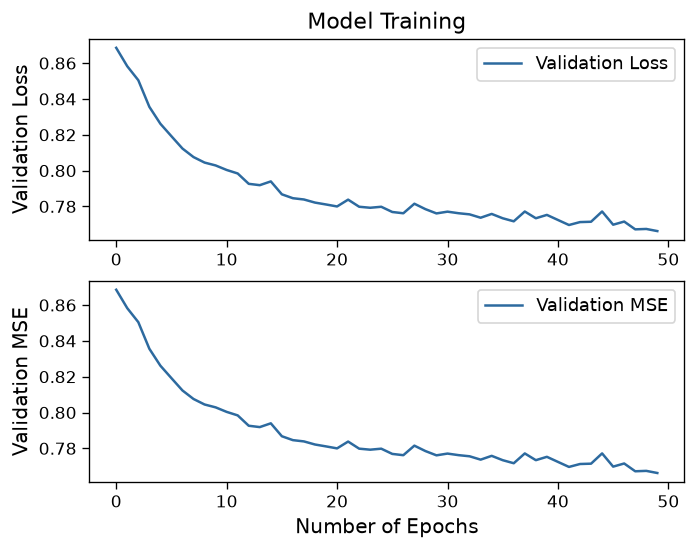

In [20]:
model_ft = train_model(LeOr, dataloaders, criterion, optimizer_ft, scheduler, mode="regression", num_epochs=50)

## Save the trained LectinOracle model and the associated configuration re-quired for later inference.

In [21]:
torch.save({"model_state_dict": model_ft.state_dict(), "lib": dict(lib),
    "data_min": float(data_min), "data_max": float(data_max)},MODEL_CHECKPOINT)

# 2. Running Binding Predictions

## Preparing and Canonicalizing Glycan Inputs

In [22]:
glycans = [column for column in binding_df.columns if column != "target"]
glycans = [canonicalize_iupac(g) for g in glycans]

## Preparing Lectin Inputs (the human Galectin-3 (P17931) sequence) and Generating ESMC Sequence Representations.

In [23]:
query_lectin = (
    "MADNFSLHDALSGSGNPNPQGWPGAWGNQPAGAGGYPGASYPGAYPGQAPPGAYPGQAPP"
    "GAYPGAPGAYPGAPAPGVYPGPPSGPGAYPSSGQPSATGAYPATGPYGAPAGPLIVPYNL"
    "PLPGGVVPRMLITILGTVKPNANRIALDFQRGNDVAFHFNPRFNENNRRVIVCNTKLDNN"
    "WGREERQSVFPFESGKPFKIQVLVEPDHFKVAVNDAHLLQYNHRVKKLNEISKLGISGDI"
    "DLTSASYTMI"
)

model = ESMC.from_pretrained("esmc_300m")
query_lectin_dict = get_esmc_representations([query_lectin], model)


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

## Loading LectinOracle model.

In [24]:
# # Option 1: load the model saved above with PyTorch
# checkpoint = torch.load(MODEL_CHECKPOINT, map_location=device, weights_only=True)
# lib = HashableDict(checkpoint["lib"])
# lectinoracle = LectinOracle(
#     input_size_prot=960,
#     input_size_glyco=len(lib) + 1,
#     hidden_size=128,
#     num_classes=1,
#     data_min=checkpoint["data_min"],
#     data_max=checkpoint["data_max"],
# ).to(device)
# lectinoracle.load_state_dict(checkpoint["model_state_dict"])
# lectinoracle.eval()

# Option 2
lectinoracle = prep_model("LectinOracle", 1, trained = True)

Download completed.


## The get lectin preds() function accepts the query lectin sequence and its embedding dictionary along with a trained LectinOracle model and list of glycans as its main inputs.

In [25]:
prediction_df = get_lectin_preds(query_lectin, glycans, lectinoracle,
    query_lectin_dict, background_correction = False)  # If option 1 else remove this argument libr=lib

prediction_df = prediction_df[["motif", "pred"]]
prediction_df.to_csv(DATA_DIR / "prediction_df.csv", index=False)

# 3. Motif Enrichment and Downstream Analysis

## Running the output of get lectin preds() through the get pvals motifs() function returns enriched motifs among the predicted-to-be-bound glycans for a query lectin. 

In [26]:
motif_input_df = prediction_df.rename(columns={"pred": "target"})
motif_pvals = get_pvals_motifs(motif_input_df,label_col_name="target",
    zscores=False, thresh=1.645, feature_set=["exhaustive"])

motif_pvals.to_csv(DATA_DIR / "motif_pvals.csv")

## Path configuration and threshold adjustment.

In [27]:
DATA_DIR = Path("data")
PREDICTION_FILE = DATA_DIR / "prediction_df.csv"
MOTIF_PVALS_FILE = DATA_DIR / "motif_pvals.csv"
OUTPUT_DIR = DATA_DIR / "specificity_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TOP_N = 20
DRAW_TOP_N = 10
BINDER = 1.00
STRONG_BINDER = 1.645
NONBINDER = 0

## Profile specificity across the glycan panel. 

In [28]:
# Loading and standardizing prediction results
prediction_df = pd.read_csv(PREDICTION_FILE)
prediction_df = prediction_df[["motif", "pred"]].rename(columns={"motif": "glycan"})

# Calculating percentile scores and prediction ranks
prediction_df["score_percentile"] = prediction_df["pred"].rank(method="average", pct=True) * 100
profile_df = prediction_df.sort_values("pred", ascending=False).reset_index(drop=True)
profile_df["rank"] = np.arange(1, len(profile_df) + 1)

# Category assignment
profile_df["binding_call"] = "Background"
profile_df.loc[profile_df["pred"] < NONBINDER, "binding_call"] = "Non-binder"
profile_df.loc[profile_df["pred"] >= BINDER, "binding_call"] = "Binder"
profile_df.loc[profile_df["pred"] >= STRONG_BINDER, "binding_call"] = "Strong binder"

## Visualize ranked specificity across the panel.

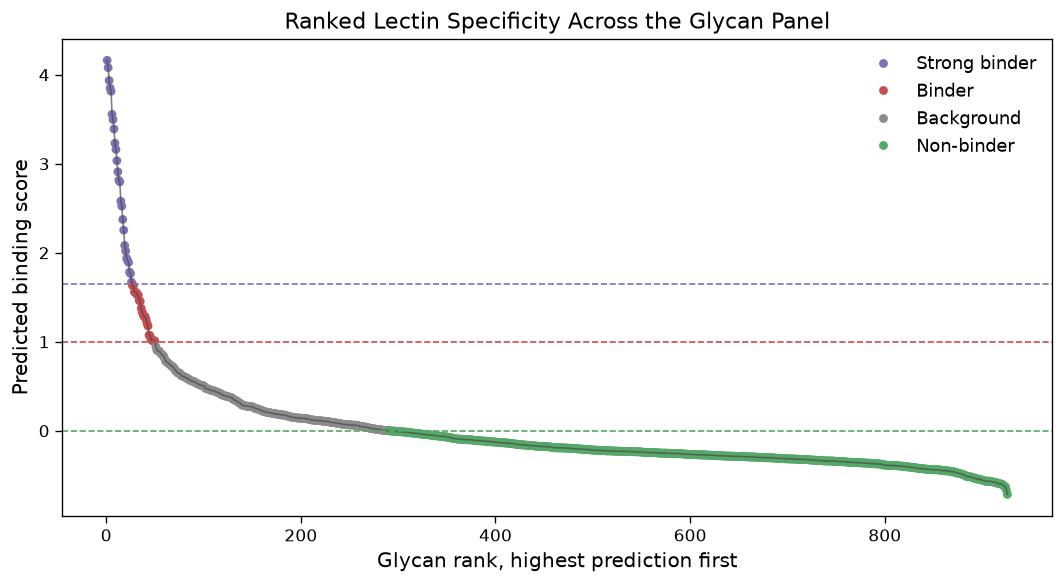

In [29]:
palette = {
    "Strong binder": "#8172B2",
    "Binder": "#C44E52",
    "Background": "#8C8C8C",
    "Non-binder": "#55A868",
}

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(profile_df["rank"], profile_df["pred"], color="#4A4A4A", linewidth=1, alpha=0.7)
sns.scatterplot(
    data=profile_df,
    x="rank",
    y="pred",
    hue="binding_call",
    palette=palette,
    s=28,
    linewidth=0,
    ax=ax,
)
ax.axhline(BINDER, color=palette["Binder"], linestyle="--", linewidth=1)
ax.axhline(STRONG_BINDER, color=palette["Strong binder"], linestyle="--", linewidth=1)
ax.axhline(NONBINDER, color=palette["Non-binder"], linestyle="--", linewidth=1)
ax.set_title("Ranked Lectin Specificity Across the Glycan Panel")
ax.set_xlabel("Glycan rank, highest prediction first")
ax.set_ylabel("Predicted binding score")
ax.legend(frameon=False, title="")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ranked_specificity_curve.pdf", dpi=300, bbox_inches="tight")
plt.show(fig)

## Visualize the binding-score distribution

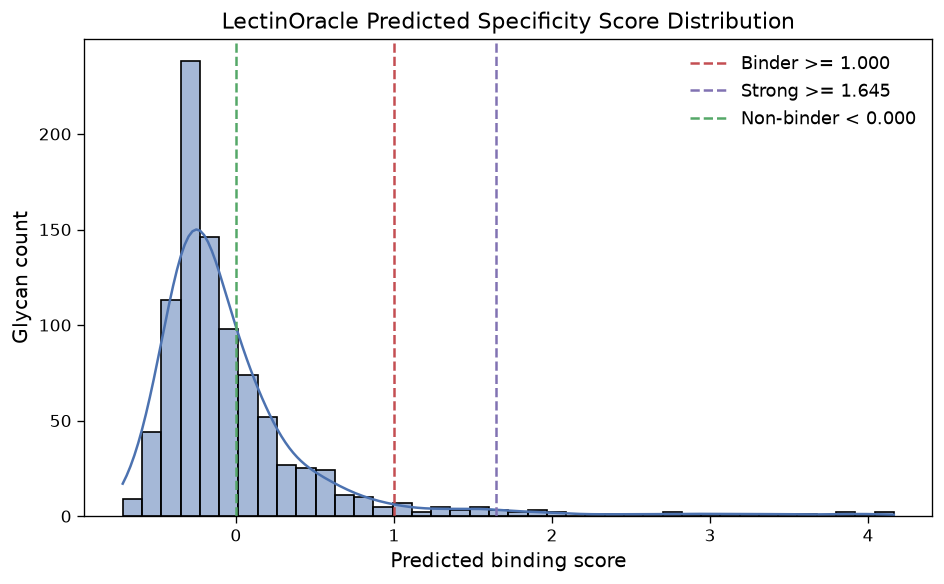

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(profile_df["pred"], bins=40, kde=True, color="#4C72B0", ax=ax)
ax.axvline(BINDER, color=palette["Binder"], linestyle="--", linewidth=1.5, label="Binder >= 1.000")
ax.axvline(STRONG_BINDER, color=palette["Strong binder"], linestyle="--", linewidth=1.5, label="Strong >= 1.645")
ax.axvline(NONBINDER, color=palette["Non-binder"], linestyle="--", linewidth=1.5, label="Non-binder < 0.000")
ax.set_title("LectinOracle Predicted Specificity Score Distribution")
ax.set_xlabel("Predicted binding score")
ax.set_ylabel("Glycan count")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "score_distribution.pdf", dpi=300, bbox_inches="tight")
plt.show(fig)

## Draw the top-ranked glycan structures using GlycoDraw.

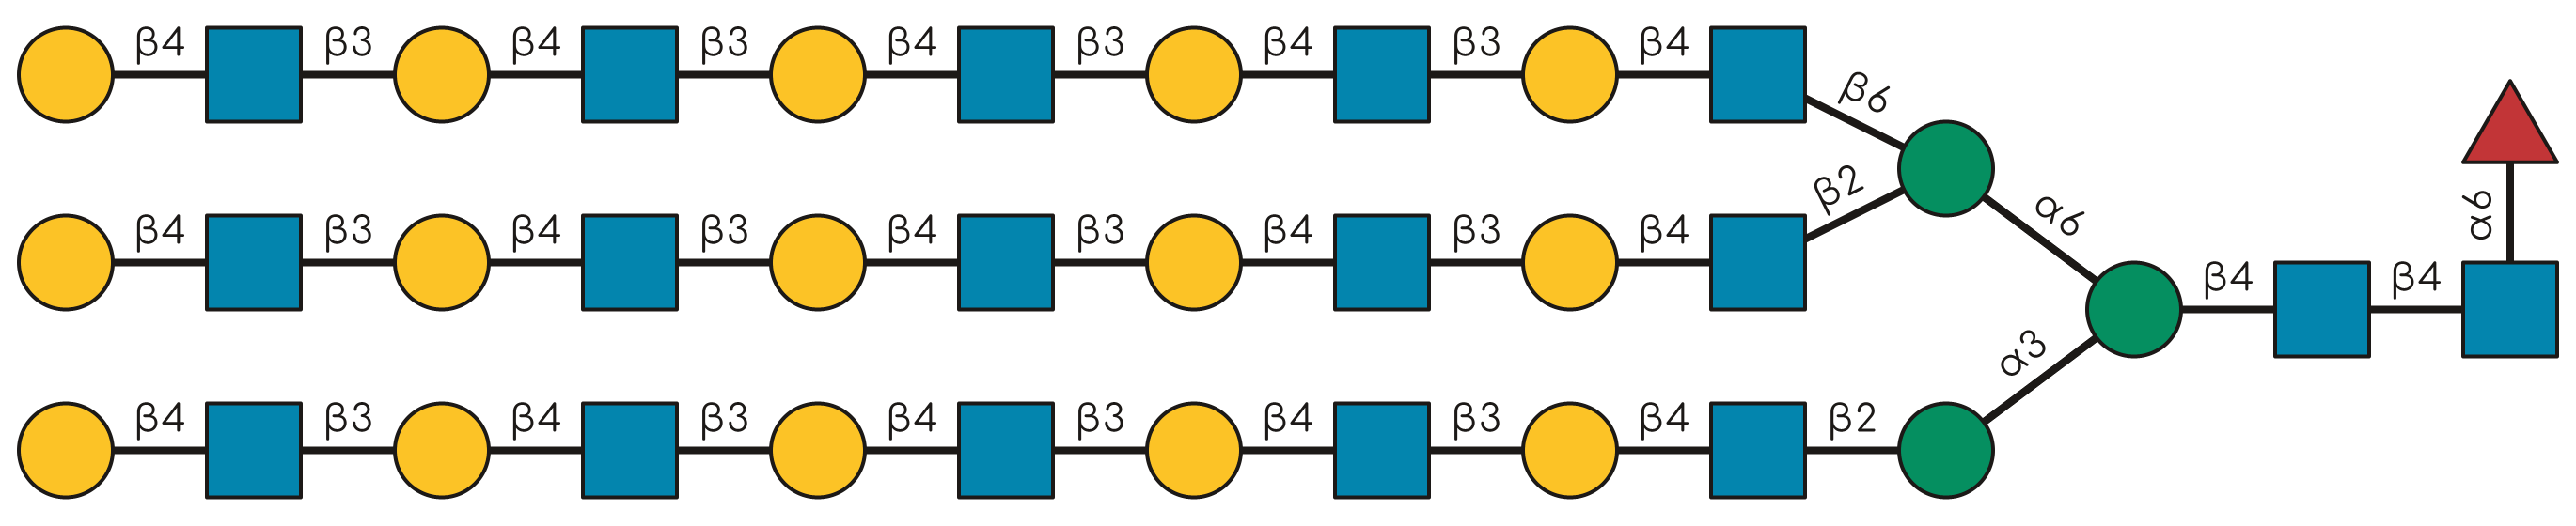

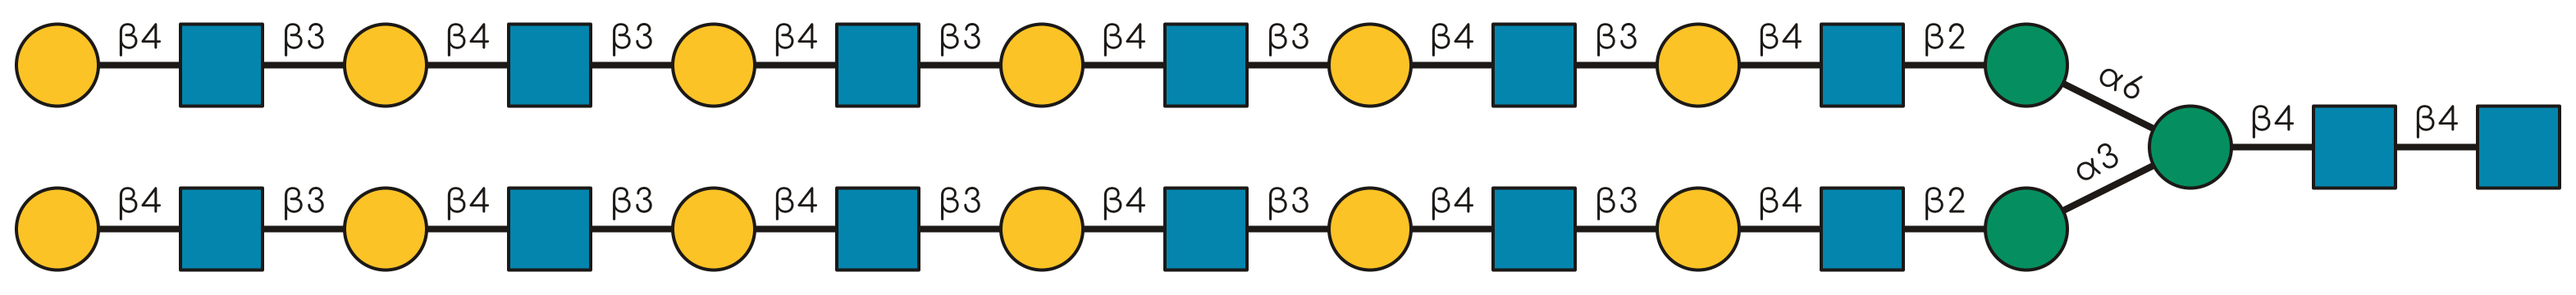

In [43]:
from IPython.display import display
for _, row in profile_df.head(2).iterrows():
    structure_file = OUTPUT_DIR / f"rank_{int(row['rank']):02d}.pdf"
    display(
        GlycoDraw(
            row["glycan"],
            suppress=True,
            compact=False,
            show_linkage=True,
            restrict_vocab=True,
            filepath=structure_file,
        )
    )

## Load and filter motif enrichment results generated during inference. 

In [33]:
motif_pvals = pd.read_csv(MOTIF_PVALS_FILE)
enriched_motifs = motif_pvals[
    motif_pvals["significant"] & (motif_pvals["effect_size"] > 0)].copy()
enriched_motifs = enriched_motifs.sort_values(["corr_pval", "effect_size"], ascending=[True, False])

top_determinant_motifs = enriched_motifs.sort_values(["effect_size", "corr_pval"], ascending=[False, True]).head(TOP_N)

## Visualize top binding motifs

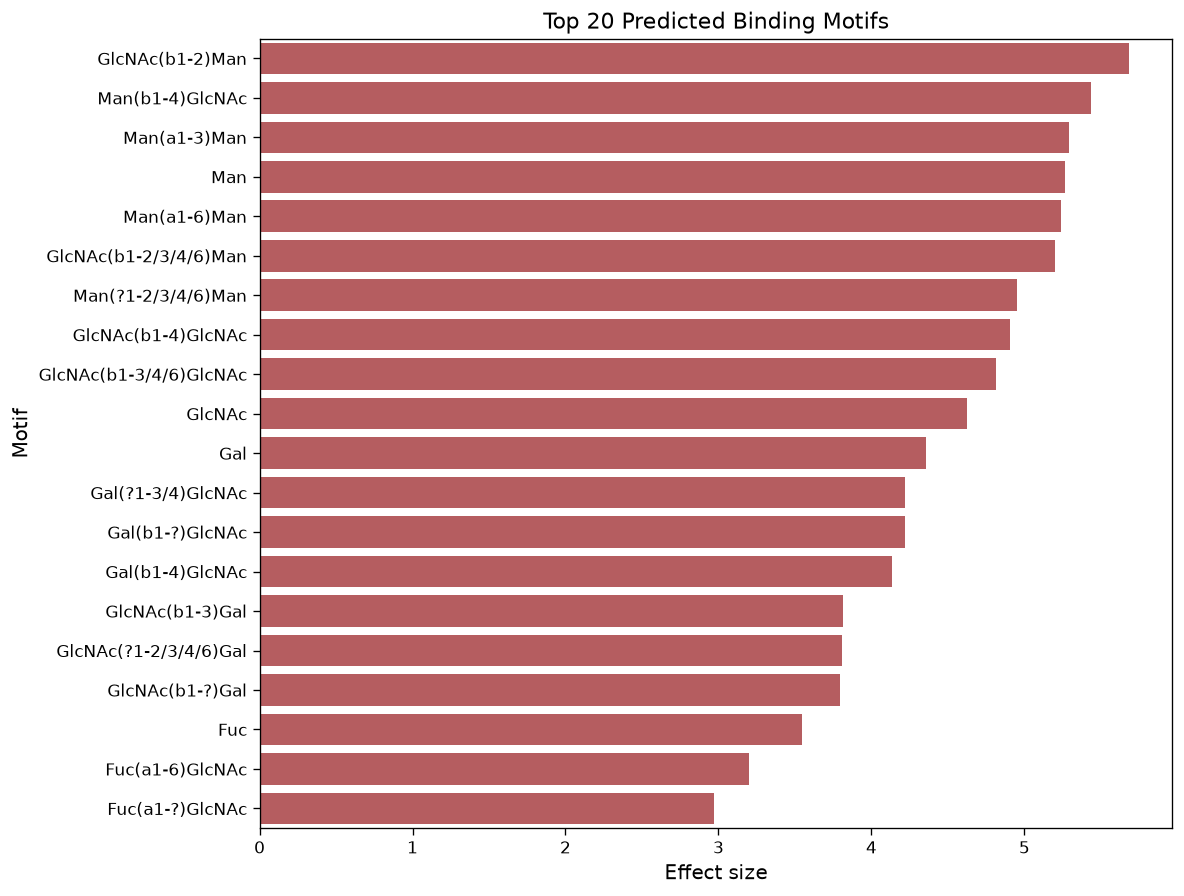

In [34]:
determinant_plot_df = top_determinant_motifs.copy()
determinant_plot_df["label"] = determinant_plot_df["motif"].map(
    lambda motif: textwrap.shorten(str(motif), width=72, placeholder="...")
)

fig, ax = plt.subplots(figsize=(10, max(6, len(determinant_plot_df) * 0.38)))
sns.barplot(
    data=determinant_plot_df,
    x="effect_size",
    y="label",
    order=determinant_plot_df["label"].tolist(),
    color=palette["Binder"],
    ax=ax,
)
ax.set_title(f"Top {len(determinant_plot_df)} Predicted Binding Motifs")
ax.set_xlabel("Effect size")
ax.set_ylabel("Motif")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "top_determinant_motifs.pdf", dpi=300, bbox_inches="tight")
plt.show(fig)